# Wang et al. 2019 — Glioblastoma (Brain) · 01 Preprocessing

Malignant-cell load → per-sample threshold (gap-finding) → overdispersed genes → PCA → Harmony on `sample` (iLISI sweep) → UMAP → detached-island removal → Leiden → GBM cellular-state annotation (data markers cross-referenced to the publication meta-programs).

**Gate 1 (01→02):** is the malignant structure both sample-integrated *and* one continuous connected manifold? Judged on the regenerated embedding across an integration-strength sweep with a per-neighborhood metric (iLISI); biology settled before the call.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # 'Wang2019_Brain-2'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Brain'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
raw_name = 'Data_' + name.split('-')[0]                 # strip the '-2' re-run suffix for the raw dir
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw dir:', raw_name)

dataset: Wang2019_Brain-2 | category: Brain | raw dir: Data_Wang2019_Brain


In [3]:
# load malignant cells (single 10x leaf; loader: normalize_total + log1p on UMIcounts)
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('all cells by type:', adata.obs.cell_type.value_counts().to_dict())
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
print('malignant:', adata.shape, '| expression = log1p(normalize_total(UMIcounts)), Xmax %.2f' % adata.X.max())
adata

all cells by type: {'Malignant': 9916, 'Oligodendrocyte': 3711, 'Myeloid': 2396, 'Astrocyte': 248, 'Endothelial': 46}
malignant: (9916, 33545) | expression = log1p(normalize_total(UMIcounts)), Xmax 7.51
Out[3]: 
AnnData object with n_obs × n_vars = 9916 × 33545
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype'
    uns: 'log1p'


AnnData object with n_obs × n_vars = 9916 × 33545
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'celltype'
    uns: 'log1p'

In [4]:
# this dataset ships no cell-cycle phase (all NaN) -> compute it (Tirosh S / G2M gene sets)
adata.obs = adata.obs.drop(columns=['g1s_score','g2m_score','cell_cycle_phase'])
s_genes=['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','MLF1IP','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes=['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['cell_cycle_phase'] = adata.obs['phase'].astype(str)
print('computed cell-cycle phases:', adata.obs['phase'].value_counts().to_dict())

computed cell-cycle phases: {'G1': 8035, 'S': 970, 'G2M': 911}


In [5]:
# DERIVED sample threshold — largest ratio gap in sorted per-sample counts, cut at the geometric mean
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]; gap = int(np.argmax(ratios))
thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.values.tolist())
print('adjacent ratios      :', np.round(ratios,2).tolist())
print(f'largest gap {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})  =>  threshold = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [2732, 2492, 1293, 1112, 938, 687, 396, 143, 85, 38]
adjacent ratios      : [1.1, 1.93, 1.16, 1.19, 1.37, 1.73, 2.77, 1.68, 2.24]
largest gap 396 -> 143 (ratio 2.77)  =>  threshold = 237
kept 7/10 samples -> 9650 cells


In [6]:
# gene filter + overdispersed selection (scFates GAM residuals)
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2113 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2113


In [7]:
# per-neighborhood integration metric (iLISI): ideal ~n_samples when fully mixed
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, cnt = np.unique(lab[idx[i]], return_counts=True); p = cnt/cnt.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'iLISI sweep over theta x n_pcs (ideal ~{nsamp} = full sample mixing):')
print('  pre-Harmony PCA   npcs=20: %.2f | npcs=40: %.2f' %
      (ilisi(adata.obsm['X_pca'][:,:20], s), ilisi(adata.obsm['X_pca'][:,:40], s)))
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    row = ' | '.join('npcs=%d: %.2f' % (p, ilisi(adata.obsm['X_pca_harmony'][:,:p], s)) for p in [20,30,40])
    print(f'  theta={th:2d}   {row}')

iLISI sweep over theta x n_pcs (ideal ~7 = full sample mixing):
  pre-Harmony PCA   npcs=20: 1.03 | npcs=40: 1.04
  theta= 2   npcs=20: 1.69 | npcs=30: 1.65 | npcs=40: 1.65
  theta= 5   npcs=20: 2.43 | npcs=30: 2.34 | npcs=40: 2.32
  theta=10   npcs=20: 2.60 | npcs=30: 2.48 | npcs=40: 2.45


In [8]:
# selected integration: mixing rises 1.0 -> ~2.6 and plateaus (theta 5->10); n_pcs 20/40 near-identical,
# so 20 is in the robust range and not under-powered (avoids the Chen-2020 n_pcs=6 failure mode).
theta, n_pcs = 10, 20
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print(f'selected theta={theta}, n_pcs={n_pcs}')

selected theta=10, n_pcs=20


In [9]:
# remove detached islands: UMAP radius graph at 6x median NN distance, keep largest component
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached islands removed:', int((lab != main).sum()), 'cells in', ncomp-1, 'islands')
adata = adata[lab == main].copy()
# rebuild graph + embedding on retained cells for a clean manifold
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells')

detached islands removed: 18 cells in 2 islands
retained one connected component: 9632 cells


In [10]:
# GBM cellular-state annotation: data-derived marker scores cross-referenced to the publication
# meta-programs (obs['mp_assignment']). States = Neftel 2019 AC / MES / OPC / NPC-like.
state_markers = {
  'AC-like' : ['GFAP','AQP4','S100B','MLC1','HOPX','CLU','SPARCL1','AGT'],
  'MES-like': ['CHI3L1','ANXA1','ANXA2','CD44','VIM','LGALS1','LGALS3','ADM','VEGFA','HILPDA'],
  'OPC-like': ['OLIG1','OLIG2','PDGFRA','CSPG4','SOX10','APOD','BCAN'],
  'NPC-like': ['DLL3','SOX4','SOX11','DCX','STMN2','CD24','TUBB3','ELAVL4']}
for st, gl in state_markers.items():
    sc.tl.score_genes(adata, [g for g in gl if g in adata.var_names], score_name=st, random_state=SEED)
sc.tl.leiden(adata, resolution=0.3, key_added='leiden', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
means = adata.obs.groupby('leiden', observed=True)[list(state_markers)].mean()
cl2state = means.idxmax(axis=1).to_dict()
adata.obs['celltype'] = adata.obs['leiden'].map(cl2state).astype('category')
print('Leiden cluster -> GBM state:', cl2state)
print('state composition:', adata.obs['celltype'].value_counts().to_dict())
ct = pd.crosstab(adata.obs['celltype'], adata.obs['mp_assignment'])
print('\nconcordance with publication meta-programs (top 3 per assigned state):')
for st in ct.index:
    print(f'  {st}: {ct.loc[st].sort_values(ascending=False).head(3).to_dict()}')

Leiden cluster -> GBM state: {'0': 'AC-like', '1': 'AC-like', '2': 'AC-like', '3': 'AC-like', '4': 'OPC-like', '5': 'NPC-like'}
state composition: {'AC-like': 6293, 'OPC-like': 1789, 'NPC-like': 1550}

concordance with publication meta-programs (top 3 per assigned state):
  AC-like: {'Astrocytes': 726, 'Hypoxia': 548, 'MES (glioma)': 245}
  NPC-like: {'NPC/OPC': 168, 'NPC Glioma': 63, 'Cell Cycle - G1/S': 23}
  OPC-like: {'Oligo Progenitor': 434, 'NPC/OPC': 22, 'NPC Glioma': 13}


7 samples share one continuous connected manifold; sample iLISI = 2.60.
GATE 1: samples intermixed (iLISI 1.0 -> 2.60) on one connected component -> GO


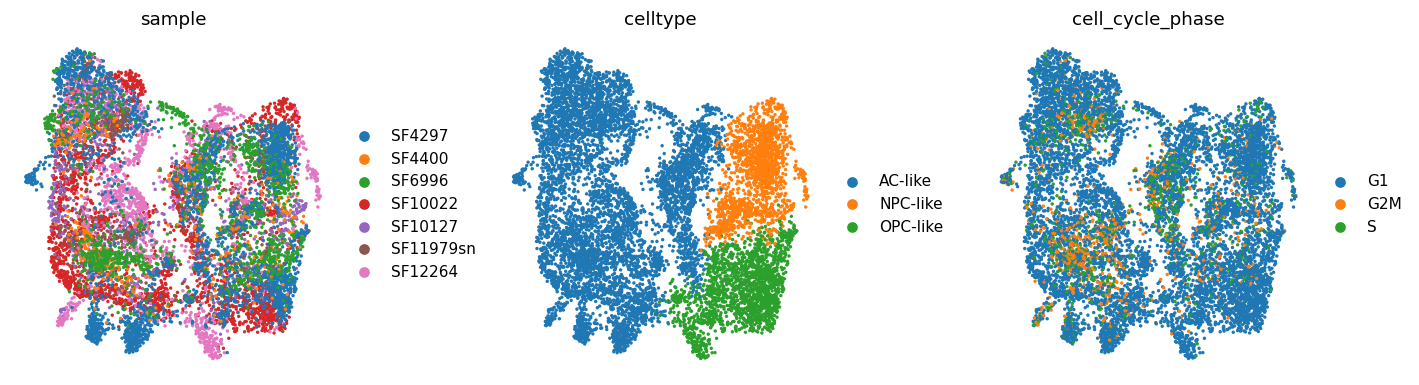

In [11]:
# GATE 1 evidence — samples intermixed on one continuous manifold; states + cell cycle for biology
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['sample', 'celltype', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=20, frameon=False, show=False, ax=ax, title=col)
plt.tight_layout(); plt.show()
il = ilisi(adata.obsm['X_pca_harmony'][:,:n_pcs], adata.obs['sample'].values)
print(f'{adata.obs["sample"].nunique()} samples share one continuous connected manifold; sample iLISI = {il:.2f}.')
print('GATE 1: samples intermixed (iLISI 1.0 -> %.2f) on one connected component -> GO' % il)

In [12]:
# save processed data
for k in adata.obs.columns:
    if adata.obs[k].dtype == object: adata.obs[k] = adata.obs[k].astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (9632, 26409)


saved samples.pdf | cells: 9632


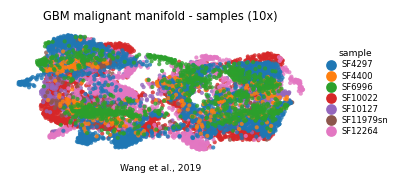

In [13]:
# samples.pdf — house (3.5,1.5) linear-trajectory strip, sample-coloured (Gate-1 integration evidence)
plot = adata.copy(); xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('GBM malignant manifold - samples (10x)', size=7.5)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig, 'samples.pdf'), bbox_inches='tight'); plt.show()
print('saved samples.pdf | cells:', plot.shape[0])